In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import os
import json
import sys
import h5py
import pandas as pd
import ipywidgets as widgets

from scipy.optimize import nnls
from scipy.ndimage import binary_erosion, binary_dilation
from skimage.transform import downscale_local_mean
sys.path.append("/home/ucfacb0/ARIA/Level_1_Retrievals")
from load_data import load_data
from astropy.convolution import convolve, Gaussian2DKernel

from utils import *
cm = 1/2.54

In [2]:
# Load data
platform = "sd"
site_name = "JQ_LC4396B"
launch_ind = 0

In [3]:
######################################################
# Now we know the platform, set some global variables.
###################################################### 

# Load the copernicus configuration. 
# We need this for the compute_cloudmask function.
if platform in ["ls","sn"]:
    
    config = SHConfig()
    config.sh_base_url = 'https://sh.dataspace.copernicus.eu'
    config.sh_token_url = 'https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token'
    # Error check to make sure credentials have been provided:
    if not config.sh_client_id or not config.sh_client_secret:
        print("Warning! To use Process API, please provide the credentials (OAuth client ID and client secret).")

clips =       {"ls":0.3,
               "sn":5000,
               "sd":0.3}
resolutions = {"ls":30,
               "sn":60,
               "sd":3}

clip = clips[platform]
res  = resolutions[platform]

#########################################
# Now load the site information and data.
#########################################

site_data = json.load(open(f"/home/ucfacb0/ARIA/aria_data_download/matches/matches_{platform}.json"))
launch_times = site_data[site_name]["launch_times"]
launch_time = pd.to_datetime(launch_times[launch_ind])
print(f"Processing launch {launch_ind+1}/{len(launch_times)} for site {site_name} at {res}m resolution.")
center_lat   = float(site_data[site_name]["lat"])
center_lon   = float(site_data[site_name]["lon"])
era5_data, xsc_mean, data_tar, data_ref, time_tar, time_ref = load_data(site_name, launch_ind, platform, center_lat, center_lon)

############################################
# Rename the bands to a defined set of keys.
############################################

# Landsat, Sentinel and Planet all have different bandnames.
# Lets rename them all to the colour names.
band_names = {
    "ls": {"B01": "coastal_blue", "B02": "blue", "B03": "green", "B04": "red", "B05": "nir", "B06": "swir1"},
    "sn": {"B01": "coastal_blue", "B02": "blue", "B03": "green", "B04": "red", "B08": "nir", "B11": "swir1"},
    "sd": {},
}
mapping = band_names[platform]
data_tar = data_tar.rename({k: v for k, v in mapping.items() if k in data_tar})
data_ref = data_ref.rename({k: v for k, v in mapping.items() if k in data_ref})
target_band = "coastal_blue" 

# Choose a reference as the target, just to check we don't have a false positive.
#ref_check_ind = 3
#raa = data_tar["raa"]
#data_tar = data_ref.isel(time=ref_check_ind).copy()
#data_ref = data_ref.drop_isel(time=ref_check_ind)
#data_tar["raa"] = raa

Processing launch 1/1 for site JQ_LC4396B at 3m resolution.
Overpass is 37 mins after launch.
ERA5 100m wind speed at target site: 1.2 m/s blowing towards 129 degrees from north.
Plume may have travelled by 2.6 km.
ERA5 10m wind speed at target site: 1.0 m/s blowing towards 133 degrees from north.
Plume may have travelled by 2.3 km.
Grid box is 13.52 × -13.66


In [4]:
# Calculate the AMF.
sw_path = "/home/ucfacb0/ARIA/Level_1_Retrievals/data/AMFs_lookup_no2_440nm.he5"
with h5py.File(sw_path, "r") as f:
    dI0       = np.array(f["Scattering Weights/dI0"][:])      # type: ignore
    dI1       = np.array(f["Scattering Weights/dI1"][:])      # type: ignore
    dI2       = np.array(f["Scattering Weights/dI2"][:])      # type: ignore
    sza_grid  = np.array(f["Grid/SZA"][:])                    # type: ignore
    vza_grid  = np.array(f["Grid/VZA"][:])                    # type: ignore
    alb_grid  = np.array(f["Grid/Albedo"][:])                 # type: ignore   
    sp_grid   = np.array(f["Grid/Surface Pressure"][:])       # type: ignore
    alt_layer = np.array(f["Profiles/Altitude Layer"][:])     # type: ignore
    o3_labels = [s.decode() for s in f["Grid/OZO"][:]]        # type: ignore
    o3_col    = np.array(f["Profiles/Ozone Column Layer"][:]) # type: ignore

full_totals_DU = o3_col.sum(axis=0) / 2.69e16

target_lat = center_lat
if abs(target_lat) < 30:
    band = "L"
elif abs(target_lat) < 60:
    band = "M"
else:
    band = "H"
band_mask = np.array([label.startswith(band) for label in o3_labels])

# Determine the albedo for the target site.
with h5py.File("/home/ucfacb0/ARIA/Level_1_Retrievals/data/OMI-Aura_L3-OMLER_2005m01-2009m12_v003-2010m0503t063707.he5", "r") as f:
    base = "HDFEOS/GRIDS/EarthSurfaceReflectanceClimatology/Data Fields"
    wavelength   = np.array(f[f"{base}/Wavelength"][:]) # type: ignore
    ler          = np.array(f[f"{base}/MonthlySurfaceReflectance"][:]) # type: ignore
    lat_grid_ler = np.array(f[f"{base}/Latitude"][:]) # type: ignore
    lon_grid_ler = np.array(f[f"{base}/Longitude"][:]) # type: ignore

i_lat = np.argmin(np.abs(lat_grid_ler - center_lat))
i_lon = np.argmin(np.abs(lon_grid_ler - center_lon))
i_month = time_tar.month - 1  # 0-indexed
mask_wav = (wavelength >= 405) & (wavelength <= 465)
alb_val = np.mean(ler[i_month, mask_wav, i_lat, i_lon]) / 1000

def nearest_idx(grid, values):

    # Create two arrays of shape (1,1,n) and (nlat,nlon,1)
    # Subtract to get the residual between grid value and values value
    diff_grid = grid[np.newaxis, np.newaxis, :] - values[..., np.newaxis]

    # Take the absolute value and find the minimum index (closest).
    min_ind = np.argmin(np.abs(diff_grid), axis=-1)
    return min_ind

i_sza   = nearest_idx(sza_grid, data_tar["sza"].values)  # (nlat, nlon)
i_vza   = nearest_idx(vza_grid, data_tar["vza"].values)  # (nlat, nlon)
i_alb   = np.argmin(np.abs(alb_grid  - alb_val))
i_sp    = np.argmin(np.abs(sp_grid   - era5_data["sp"]))
i_z     = np.argmin(np.abs(alt_layer - era5_data["h_plume_km"])) # km
i_ozone = np.argmin(np.where(band_mask, np.abs(full_totals_DU - era5_data["ozone_DU"]), np.inf))
print(f"Ozone profile: {i_ozone} - {o3_labels[i_ozone]} ({full_totals_DU[i_ozone]:.1f} DU, ERA5: {era5_data['ozone_DU']:.1f} DU)")

# Index the dI arrays
dI0_slice = dI0[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
dI1_slice = dI1[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
dI2_slice = dI2[i_sza, i_vza, i_alb, i_z, i_sp, i_ozone]
    
# Calculate AMF
# Gonzalo confirmed that SW values in the LUTs already account for the geometric AMF.
amf = dI0_slice + dI1_slice * np.cos(np.radians(data_tar["raa"].values)) + dI2_slice * np.cos(2 * np.radians(data_tar["raa"].values))

Ozone profile: 5 - M250 (310.5 DU, ERA5: 316.9 DU)


Text(0, 0.5, 'Altitude [km]')

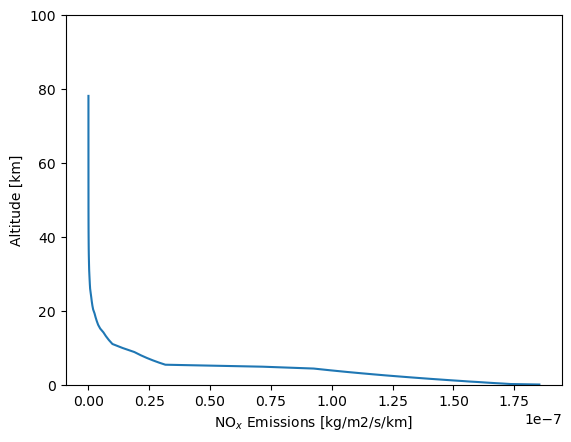

In [5]:
layer_data = np.loadtxt("/home/ucfacb0/Emission_Inventory/Emissions_API/input_files/geoschem_vertical_grid_72.csv",delimiter=",")
levs = layer_data[::-1,1]
thickness = layer_data[::-1, 2] - layer_data[::-1, 0]
ds_falcon_profile = xr.open_dataset("/home/ucfacb0/ARIA/plume_regridding/launch_emis_0.01x0.01_3x3_72L_20230218.nc4")
nox_emis = ds_falcon_profile["launch_nox_thermal"]+ds_falcon_profile["launch_nox_fuel"]
nox_emis = nox_emis.isel(time=3,lat=1,lon=1)
fig, ax = plt.subplots()
ax.plot(nox_emis/thickness,levs)
#ax.set_xlim(0,5e-8)
ax.set_ylim(0,100)
ax.set_xlabel(f"NO$_x$ Emissions [{ds_falcon_profile["launch_nox_thermal"].units}/km]")
ax.set_ylabel(f"Altitude [km]")

In [6]:
################################################
# Test out cropping and filtering on the target.
################################################

def plot_watermask(brightness_filter, NDWI_filter, NDSI_filter, crop_x, crop_y):
    
    '''
    This is a quick interactive plotting function to test out cropping and filtering for the target only.
    '''
    
    crop1, crop2 = crop_x
    crop3, crop4 = crop_y
    crop = (crop1, crop2, crop3, crop4)
    print(crop)

    filters = [brightness_filter, NDWI_filter, NDSI_filter, 0]
    water_mask_tar = compute_water_mask(data_tar, filters, platform, None)
    
    if platform == "sn":
        data_mask_union = data_tar["dataMask"].values.astype(bool)
    elif platform == "ls":
        data_mask_union = np.isfinite(data_tar[target_band].values)
    elif platform == "sd":
        data_mask_union = ~data_tar["udm2"].sel(type='udm1').values.astype(bool)
    else:
        raise ValueError(f"Unknown platform {platform}.")
        
    validland_mask = data_mask_union & (~water_mask_tar)

    total_px = data_tar[target_band].shape[0]*data_tar[target_band].shape[1]
    valid_frac = np.sum(validland_mask) / total_px * 100
    print(f"{valid_frac:.2f}% Valid Pixels")
    
    # Crop
    center_mask = compute_center_mask(crop, data_tar[target_band])
    validland_mask = validland_mask & center_mask

    fig, ax = plt.subplots(1,2)
    rgb = create_rgb(data_tar,clip)
    rgb_masked = rgb.copy()
    rgb_masked[~center_mask] = 1.0 
    ax[0].imshow(rgb_masked)
    ax[1].imshow(np.where(validland_mask, 1, 0), cmap='gray', vmin=0, vmax=1)
    for i in range(2):
        ax[i].set_aspect("equal")  
        ax[i].set_xticks([])
        ax[i].set_yticks([])
    fig.tight_layout()
    plt.show()

widgets.interact(plot_watermask,
                 brightness_filter = (80.0,100.0,0.1),
                 NDWI_filter=(0,1,0.1),
                 NDSI_filter=(0,1,0.1),
                 crop_y=widgets.FloatRangeSlider(min=0, max=1, step=0.05, value=[0.0, 1.0], description='x range'),
                 crop_x=widgets.FloatRangeSlider(min=0, max=1, step=0.05, value=[0.0, 1.0], description='y range'));

interactive(children=(FloatSlider(value=90.0, description='brightness_filter', min=80.0), FloatSlider(value=0.…

In [ ]:
#####################
# Plotting functions.
#####################

def initial_plots(mask, crop):
    ###################################################
    # Plot the target, validland mask and the clusters.
    ###################################################
    fig, ax = plt.subplots(figsize=(6, 6)) 
    rgb = create_rgb(data_tar,clip)
    ax.imshow(rgb)
    H, W = rgb.shape[:2]
    ax.plot(W/2, H/2, marker='*', color='yellow', markersize=20,markeredgecolor='black', markeredgewidth=0.8, zorder=10)
    ax.set_title(f'{site_name} - {time_tar:%Y-%m-%d} - ΔT={int(data_tar["delta_t_secs"].item()/60)} min')

    # Create red overlay (RGBA)
    overlay = np.zeros((*mask.shape, 4))  # 4 = RGBA
    overlay[..., 0] = 1.0          # Red channel
    overlay[..., 3] = mask * 0.4  # Alpha (transparency)
    ax.imshow(overlay)

    h_min, h_max, w_min, w_max = crop
    x0 = w_min * W
    y0 = h_min * H
    width = (w_max - w_min) * W
    height = (h_max - h_min) * H

    rect = Rectangle(
        (x0, y0),
        width,
        height,
        fill=False,
        edgecolor='cyan',
        linewidth=2
    )
    ax.add_patch(rect)
    
    speed = era5_data["ws_100"] 
    # Background box, bottom left (the scale bar is bottom right)
    ax.add_patch(Rectangle((0.02, 0.02), 0.30, 0.10, transform=ax.transAxes,
                        facecolor="black", alpha=0.35, zorder=18))
    ax.text(0.04, 0.07, f"{speed:.1f} m s$^{{-1}}$", transform=ax.transAxes,
            color="white", fontsize=10, fontweight="bold", ha="left", va="center", zorder=20)

    # Direction arrow (points the way the wind blows towards)
    u, v = era5_data["u100"].item(), era5_data["v100"].item()
    iax = ax.inset_axes((0.22, 0.025, 0.09, 0.09), zorder=20)
    iax.set_xlim(-1, 1); iax.set_ylim(-1, 1); iax.set_aspect("equal"); iax.axis("off")
    iax.annotate("", xy=(0.8*u/speed, 0.8*v/speed), xytext=(-0.8*u/speed, -0.8*v/speed),
                arrowprops=dict(arrowstyle="-|>", color="white", lw=1.5))
    
    ax.set_aspect("equal")  
    ax.set_xticks([])
    ax.set_yticks([])
    
    out_path = f"/home/ucfacb0/ARIA/Level_1_Retrievals/out/{platform}/{site_name}"
    filename = f"/{site_name}_{time_tar:%Y-%m-%d}_{int(data_tar["delta_t_secs"].item()/60)}_rgb.png"
    os.makedirs(out_path, exist_ok=True)
    fig.tight_layout()
    fig.savefig(out_path + filename, dpi=300, bbox_inches='tight')
    
def plot_refs(ind_ref, valid_mask, water_mask, mf_clusters, n_clusters):
        
    fig, ax = plt.subplots(1,len(ind_ref)+1,figsize = ((len(ind_ref)+1)*5,5)) 
    
    cluster_plot = np.ma.masked_where(mf_clusters == -1, mf_clusters)
    ax[0].imshow(cluster_plot, cmap=plt.colormaps['gist_rainbow'].resampled(n_clusters), interpolation='nearest')
    ax[0].set_title(f'K-means ({mf_clusters.max()+1} clusters)')
            
    for i in range(len(ind_ref)):
        rgb = create_rgb(data_ref.isel(time=ind_ref[i]),clip)
        rgb_masked = rgb.copy()

        mask = ~valid_mask | water_mask
        overlay = np.zeros((*mask.shape, 4))  # 4 = RGBA
        overlay[..., 0] = 1.0          # Red channel
        overlay[..., 3] = mask * 0.4  # Alpha (transparency)        

        #rgb_masked[~valid_mask] = 1.0 
        ax[i+1].imshow(rgb_masked)
        ax[i+1].imshow(overlay)
        ax[i+1].set_title(f"Ref {i}")
    
    for i in range(len(ind_ref)+1):
        ax[i].set_aspect("equal")  
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        
    fig.tight_layout()

def scatter_ratio_plot(ref_flat, target_flat, c, ratio, retrieval):

    # Plot the reflectance of each pixel for the target and reference scene.
    fig1, ax1 = plt.subplots(figsize=(5,5),layout="constrained")
    ax1.scatter(ref_flat, target_flat, s=5, alpha=0.5)
    x = np.linspace(ref_flat.min(), ref_flat.max(), 100)
    ax1.plot(x, x / c, label=f'Best fit')
    ax1.plot(x, x, linestyle='--', label='1:1')
    ax1.set_xlabel("Reflectance (Target-weighted Reference)")
    ax1.set_ylabel("Reflectance (Target)")
    ax1.legend(loc="upper left")
    if retrieval == 1:
        ax1.set_title(f"Valid Land Pixels (c={c:.4f})")
    else:
        ax1.set_title(f"Valid Land Non-Plume Pixels (c={c:.4f})")
    
    out_path = f"/home/ucfacb0/ARIA/Level_1_Retrievals/out/{platform}/{site_name}"
    os.makedirs(out_path, exist_ok=True)
    filename = f"/{site_name}_{time_tar:%Y-%m-%d}_{int(data_tar["delta_t_secs"].item()/60)}_scatter{retrieval}.png"
    fig1.savefig(out_path + filename, dpi=300, bbox_inches='tight')
    plt.close(fig1)
    
    # Plot the ratio of the target to reference scene.
    fig2, ax2 = plt.subplots(figsize=(5,5),layout="constrained")
    im = ax2.imshow(ratio, cmap='RdBu_r', vmin=0.9, vmax=1.1)
    ax2.set_title(f'{site_name} - {time_tar:%Y-%m-%d} - ΔT={int(data_tar["delta_t_secs"].item()/60)} min',)
    plt.colorbar(im, ax=ax2,fraction=0.046, pad=0.04, label = "Ratio = c * target / reference")
    ax2.set_xticks([])
    ax2.set_yticks([])
    
    filename = f"/{site_name}_{time_tar:%Y-%m-%d}_{int(data_tar["delta_t_secs"].item()/60)}_ratio{retrieval}.png"
    fig2.savefig(out_path + filename, dpi=300, bbox_inches='tight')
    plt.close(fig2)
    
def plot_final_image(no2_vcd, source_rate, crop, vmax):

    fig, ax = plt.subplots(figsize=(15*cm, 10*cm), layout="constrained")

    # Set up background image
    rgb = create_rgb(data_tar, clip)

    # Convert fractional bounds to pixel indices
    h_min_frac, h_max_frac, w_min_frac, w_max_frac = crop
    h, w = rgb.shape[:2]
    y_start = int(h_min_frac * h)
    y_end   = int(h_max_frac * h)
    x_start = int(w_min_frac * w)
    x_end   = int(w_max_frac * w)

    cy = h/2 - y_start
    cx = w/2 - x_start

    #fig.suptitle(f'{site_name} - {time_tar} - {source_rate:.0f} kg',fontweight='normal')         
    ax.imshow(rgb[y_start:y_end, x_start:x_end])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.plot(cx, cy, marker='*', color='yellow', markersize=10,
        markeredgecolor='black', markeredgewidth=0.8, zorder=10)
    
    # Print over land only, and set vmin to 0.
    print(np.shape(no2_vcd))
    no2_crop = no2_vcd[y_start:y_end, x_start:x_end]
    im = ax.imshow(no2_crop, cmap='magma', vmin=0, vmax=vmax)

    cbar = fig.colorbar(im, ax=ax, fraction=0.15, pad=0.02)
    cbar.set_label('NO$_2$ column enhancement (mol m$^{-2}$)', fontsize=12)
    cbar.ax.tick_params(labelsize=10)

    # Plot scalebar
    pixel_size_m = res
    length_m = 1000
    bar_px = length_m / pixel_size_m
    crop_h = y_end - y_start
    crop_w = x_end - x_start
    bar_height_px = crop_h * 0.02
    x0 = crop_w * 0.80          # right side, in pixel units of the cropped image
    y0 = crop_h * 0.95          # near the bottom (imshow origin is upper)
    
    pad_x = bar_px * 0.5
    bg = Rectangle((x0 - pad_x, y0 - bar_height_px * 4.5),
                   bar_px + 2 * pad_x, bar_height_px * 6,
                   facecolor="black", alpha=0.35, zorder=18)
    ax.add_patch(bg)

    # Draw rectangle
    rect = Rectangle((x0, y0), bar_px, bar_height_px,
                    facecolor="white", edgecolor='black', lw=1.5, zorder=20)
    ax.add_patch(rect)

    # Label
    ax.text(x0 + bar_px / 2, y0 - bar_height_px * 0.5,
            f"{int(length_m/1000)} km", color='white',
            ha='center', va='bottom',
            fontsize=12, fontweight='bold', zorder=20) 
        
    #fig.tight_layout()
    if not os.path.exists(f"out/{site_name.replace('/', '')}"):
        os.makedirs(f"out/{site_name.replace('/', '')}")

IndentationError: expected an indented block after 'for' statement on line 52 (4106009076.py, line 53)

In [ ]:
#############
# Parameters:
#############

#   - crop range
#   - number refs
#   - number clusters
#   - sigma x 2
#   - percentile x 2
#   - morph structure size
#   - morph iterations

crop = (0,1,0,1)
#crop = (0.2,0.53,0.47,0.9)
center_mask = compute_center_mask(crop, data_tar[target_band]) 
filters = [100, 0, 0, 0]
number_refs = 2
n_clusters = 1
cloud_mask = False

53.82% Valid Pixels
74.98% Valid Pixels
PCs for 99% variance: 5.


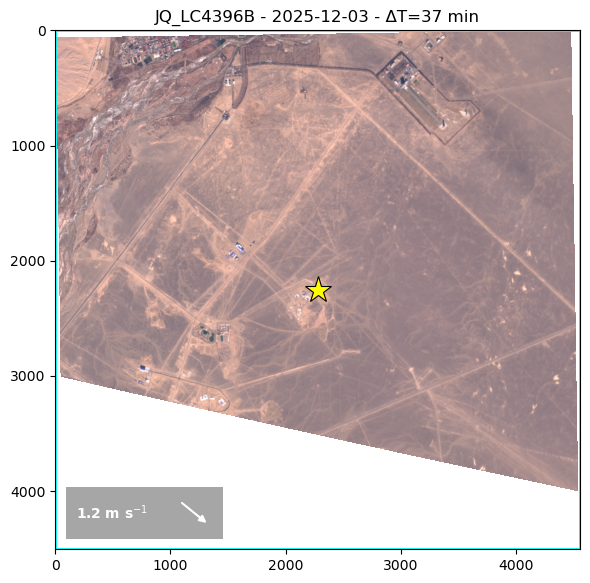

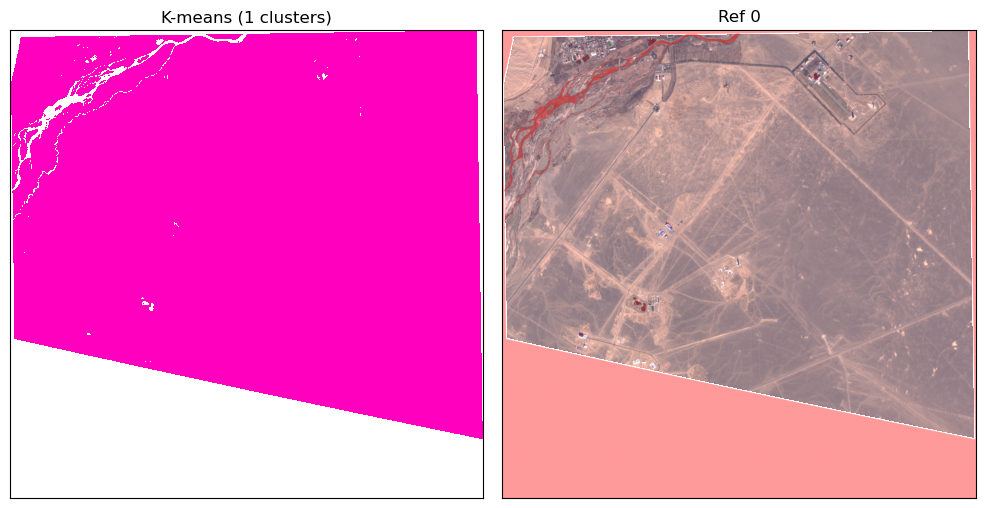

In [ ]:
# Calculate the valid, crop, and water masks across all refs and target
valid_mask, water_mask = compute_validland_mask(data_tar, data_ref, target_band, crop, filters, platform)

# For SuperDove, quota limits mean we just use the nearest references.
# Here we can choose which to use in case some aren't suitable.
if platform == "sd":
    ind_ref = [0]

# For Landsat and Sentinel, find refs with the most similar RMSE (over all valid land pixels)   
else:
    ind_ref = find_refs(valid_mask&~water_mask, data_tar, data_ref, time_ref, number_refs=number_refs)
    
if len(ind_ref) == 0:
    raise ValueError("No references found.")
    

# Now recreate the mask over the target and refs only
valid_mask, water_mask = compute_validland_mask(data_tar, data_ref, target_band, crop, filters, platform, ind_ref)

# Calculate the cloud mask (for the targets and chosen refs only, as this takes a while)
# TODO: Fix cloud mask.
if cloud_mask:
    cloud_mask = compute_cloudmask(ind_ref, platform, data_tar, time_tar, time_ref, site_name, config, center_lat, center_lon) # use omnicloudmask
    if platform == "sn" and cloud_mask is not None:
        shape = np.shape(valid_mask)
        frac = downscale_local_mean(cloud_mask.astype(float), (6, 6))
        cloud_frac  = frac[:shape[0], :shape[1]]
        cloud_mask = cloud_frac > 0
        valid_mask = valid_mask & (~cloud_mask)
    elif platform == "ls" and cloud_mask is not None:
        valid_mask = valid_mask & ~cloud_mask

# Split the target into clusters over all valid, non-water, non-cloud pixels.
# TODO: Fix cluster band names.
mf_clusters = compute_clusters(data_tar, valid_mask&~water_mask, n_clusters, platform, target_band)

# Plot.
initial_plots(~valid_mask|water_mask, crop)
plot_refs(ind_ref, valid_mask, water_mask, mf_clusters, n_clusters)

In [ ]:
def build_clustered_ref(refs, target, background_mask, mf_clusters, n_clusters,
                        min_pixels=50, fallback_w=None):
    
    """
    Solve a separate NNLS fit per k-means cluster and assemble a single
    reference scene where each pixel uses its own cluster's weights.

    refs            : (N_refs, H, W)
    target          : (H, W)
    background_mask : (H, W) bool — valid land, non-plume pixels to fit on
    mf_clusters     : (H, W) int  — cluster labels, -1 = unassigned
    """
    
    N = refs.shape[0]
    ref = np.zeros_like(target, dtype=float)
    weights_per_cluster = {}

    # Global fallback fit (used for clusters with too few background pixels)
    if fallback_w is None:
        m = background_mask
        fallback_w, _ = nnls(refs[:, m].T, target[m])

    for k in range(n_clusters):
        cluster_mask = (mf_clusters == k)
        fit_mask = cluster_mask & background_mask    # fit only on good pixels
        n_fit = int(np.sum(fit_mask))

        if n_fit >= min_pixels:
            w_k, _ = nnls(refs[:, fit_mask].T, target[fit_mask])
        else:
            w_k = fallback_w
            print(f"Cluster {k}: only {n_fit} background px — using global fallback.")
        weights_per_cluster[k] = w_k

        # Apply this cluster's weights to ALL pixels in the cluster
        # (including plume pixels, which we still need a reference for).
        ref_k = sum(w_k[i] * refs[i] for i in range(N))
        ref[cluster_mask] = ref_k[cluster_mask]

    # Pixels with no cluster label (-1): fill with the global fallback fit.
    unassigned = (mf_clusters == -1)
    if np.any(unassigned):
        ref_fb = sum(fallback_w[i] * refs[i] for i in range(N))
        ref[unassigned] = ref_fb[unassigned]

    print("Per-cluster reference weightings:")
    for k, w_k in weights_per_cluster.items():
        print(f"  Cluster {k}: {np.round(w_k, 4)}")

    return ref, weights_per_cluster

def calc_retrieval(target, ref, valid_mask, water_mask, plume_mask):

    # If theres a plume mask, create a non-plume, valid land pixel mask.
    mask = valid_mask & ~water_mask
    if plume_mask is not None:
        retrieval = 2
        mask = mask & ~plume_mask
    else:
        retrieval = 1

    # Flatten everything so its one line of pixels and calculate the scale factor.
    # The ratio should always be calculated over valid, non-water, non-cloud pixels.
    flattened_mask = mask.flatten()
    ref_flat    = ref.flatten()[flattened_mask]
    target_flat = target.flatten()[flattened_mask]
    c = (ref_flat @ target_flat) / (target_flat @ target_flat)
    print(f"Scale factor (c): {c:.4f}")
    
    # Equation 1 - Normalized Reflectance Ratio
    # Valid pixels only, exclude water, exclude cloud.
    ratio = np.full_like(target, np.nan)
    ratio[valid_mask & ~water_mask] = c * target[valid_mask & ~water_mask] / ref[valid_mask & ~water_mask]

    # Equation 2 - NO2 slant column enhancements  [mol m-2]
    no2_scd = (-1) * np.log(ratio) / xsc_mean

    # Equation 3 - Vertical columns  [mmol m-2]
    no2_vcd = (no2_scd / amf)
    
    # Check how similar the target and reference are in the background (non-plume) pixels.
    valid = np.isfinite(ratio)
    q = np.nanpercentile(ratio[mask & valid]* 100, [5, 95])
    print(f"5-95 ratio percentile: {q[1]-q[0]:.2f}%")
    bg = ratio[mask & valid]
    bg_err = np.nanstd(bg) * 100
    print(f"1σ background ratio dispersion: {bg_err:.2f}%")

    # Save an image showing some diagnostics.
    scatter_ratio_plot(ref_flat, target_flat, c, ratio, retrieval)
    return no2_vcd

def isolate_plume(no2_vcd, sigma, percentile):
    # Smooth using astropy to handle NaNs.
    kernel = Gaussian2DKernel(x_stddev=sigma)
    no2_smooth = convolve(no2_vcd, kernel, nan_treatment="interpolate", preserve_nan=True)
    threshold  = np.nanpercentile(no2_smooth, percentile)
    plume_mask = (no2_smooth > threshold)
    display_mask = plume_mask & valid_mask
    no2_plume = np.ma.masked_where(~display_mask, no2_vcd)

    return no2_smooth, no2_plume, plume_mask

def tweak_morphology(sigma,percentile,morph_struct_size):

    no2_smooth, no2_plume, plume_mask = isolate_plume(no2_vcd, sigma, percentile)

    # Alternating erosion/dilation of the plume mask to remove artifacts (2nd retrieval only)
    struct = np.ones((morph_struct_size, morph_struct_size))
    for i in range(2):
        plume_mask = binary_dilation(binary_erosion(plume_mask, struct), struct)
        plume_mask = binary_erosion(binary_dilation(plume_mask, struct), struct)
    display_mask = plume_mask & valid_mask
    no2_final = np.ma.masked_where(~display_mask, no2_vcd)

    fig, ax = plt.subplots(1,4, figsize=(20, 5))
    rgb = create_rgb(data_tar, clip)
    # Convert fractional bounds to pixel indices
    h_min_frac, h_max_frac, w_min_frac, w_max_frac = crop
    h, w = rgb.shape[:2]
    y_start = int(h_min_frac * h)
    y_end   = int(h_max_frac * h)
    x_start = int(w_min_frac * w)
    x_end   = int(w_max_frac * w)
    cy = h/2 - y_start
    cx = w/2 - x_start
    plot_arrays = [no2_vcd,no2_smooth,no2_plume,no2_final]
    plot_titles = ["VCD","VCD Smoothed","Isolated Plume","Artifacts Removed"]
    for i in range(4):
        ax[i].imshow(rgb[y_start:y_end, x_start:x_end])
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].plot(cx, cy, marker='*', color='yellow', markersize=10,
               markeredgecolor='black', markeredgewidth=0.8, zorder=10)
        max_range = np.nanmax(np.abs(no2_smooth[center_mask]))
        print(max_range)
        ax[i].imshow(plot_arrays[i][y_start:y_end, x_start:x_end], vmin=-max_range, vmax=max_range, cmap='magma')
        ax[i].set_title(plot_titles[i])
    fig.tight_layout()

In [ ]:
###############
# Retrieval 1
###############

target = data_tar[target_band].values                    #         (H, W) - target scene
refs   = data_ref[target_band].isel(time=ind_ref).values # (N_refs, H, W) - reference scenes

# Calculate the weighted references with over non-plume, valid, non-water, non-cloud pixels.
ref, weights_per_cluster = build_clustered_ref(refs, target, valid_mask&~water_mask, mf_clusters, n_clusters)

# First retrieval to get the plume mask.
no2_vcd = calc_retrieval(target,
                         ref,
                         valid_mask,
                         water_mask,
                         None)


no2_smooth, no2_plume, plume_mask = isolate_plume(no2_vcd, 3, 75)

do_retrieval_2 = True
if do_retrieval_2:

    ###############
    # Retrieval 2
    ###############

    # Calculate the linear weighted references with over non-plume valid land pixels.
    background_mask = valid_mask &~water_mask & ~plume_mask
    ref, weights_per_cluster = build_clustered_ref(refs, target, background_mask, mf_clusters, n_clusters)

    # Second retrieval to get the final plume.
    no2_vcd = calc_retrieval(target,
                             ref, 
                             valid_mask,
                             water_mask,
                             plume_mask)

    widgets.interact(tweak_morphology, sigma = (1,3,0.1), percentile=(75,100,1), morph_struct_size=(1,10,1))

Per-cluster reference weightings:
  Cluster 0: [0.9825]
Scale factor (c): 0.9993
5-95 ratio percentile: 5.04%
1σ background ratio dispersion: 1.83%


SNR is 1.30772864818573.
1408 kg of NOx emitted during the overpass.
Range is 927 - 2363 kg of NOx.
(4506, 4556)


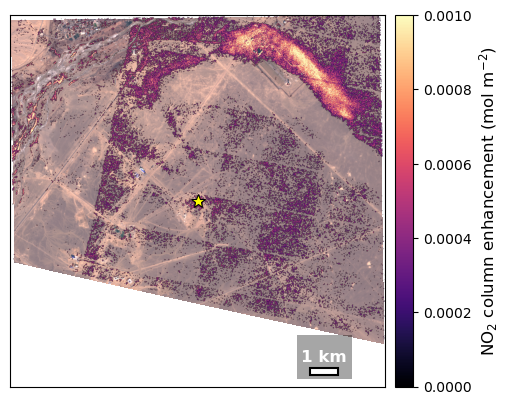

In [ ]:
sigma = 3
percentile = 75
morph_struct_size = 5

no2_smooth, _, plume_mask = isolate_plume(no2_vcd, sigma, percentile)

struct = np.ones((morph_struct_size, morph_struct_size))
for i in range(2):
    plume_mask = binary_dilation(binary_erosion(plume_mask, struct), struct) # remove artifacts
    plume_mask = binary_erosion(binary_dilation(plume_mask, struct), struct) # close holes

display_mask = plume_mask & valid_mask
no2_plume = np.ma.masked_where(~display_mask, no2_vcd)
    
# Final SNR check
# TODO: Check all the masks here.
background_mask = valid_mask & ~water_mask & ~plume_mask   # we've now reproduced plume_mask, so update background_mask
sigma_noise = np.nanstd(no2_vcd[background_mask & np.isfinite(no2_vcd)])
mu_plume    = np.nanmean(no2_vcd[plume_mask & np.isfinite(no2_vcd)])
snr = mu_plume / sigma_noise
print(f"SNR is {snr}.")

#######################
# Emission Calculation
#######################

mw_no2 = 0.04601  # kg/mol
pixel_area = res ** 2 # m2
ime_no2 = np.nansum(no2_plume * pixel_area)  # mol of NO2 (sum over plume pixels)

L_eff = [1.38,1.74,2.14]
tau = [1*60*60,2*60*60,5*60*60]

imes = []
for t in tau:
    for l in L_eff:
        factor = np.exp(data_tar["delta_t_secs"] / t) if data_tar["delta_t_secs"] >= (20 * 60) else 1.0
        ime_nox = factor * mw_no2 * ime_no2 * l  # kg of NOx
        imes.append(ime_nox)

print(f"{imes[4]:.0f} kg of NOx emitted during the overpass.")
print(f"Range is {np.min(imes):.0f} - {np.max(imes):.0f} kg of NOx.")
plot_final_image(no2_plume, imes[4], crop, 0.001)

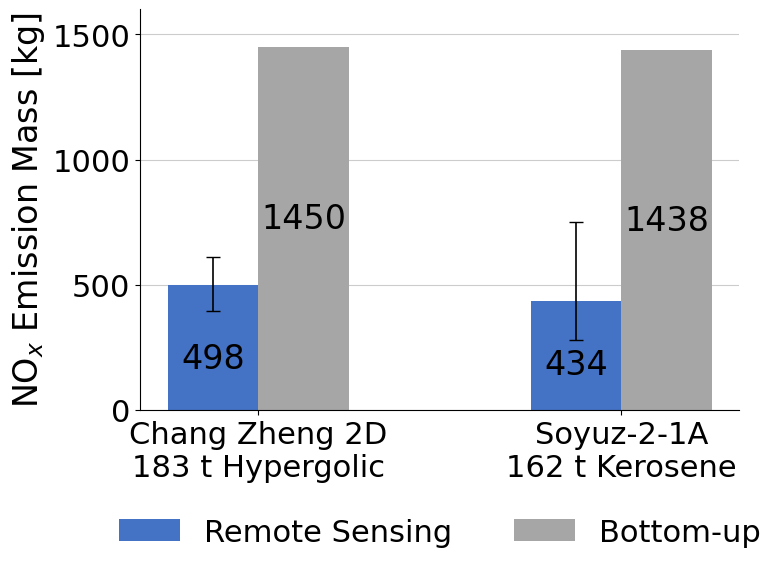

In [ ]:
sites = ['Chang Zheng 2D\n183 t Hypergolic',
         'Soyuz-2-1A\n162 t Kerosene']

sat = np.array([498,434])
inv = np.array([1450,1438])

# Replace these with your actual min/max values
sat_min = np.array([395,280])
sat_max = np.array([613,750])

# Convert to error bar format: [lower_errors, upper_errors]
sat_err = [sat - sat_min, sat_max - sat]

x = np.arange(len(sites))
width = 0.25

fig, ax = plt.subplots(figsize=(20*cm, 15*cm))

bars1 = ax.bar(x - width/2, sat, width, yerr=sat_err, capsize=5,
                label='Remote Sensing', color='#4472C4', error_kw={'elinewidth': 1.2})
bars2 = ax.bar(x + width/2, inv, width, capsize=5,
                label='Bottom-up', color='#A6A6A6', error_kw={'elinewidth': 1.2})

# Value labels above bars (offset above the upper error bar)
for i in range(len(sites)):
    ax.text(x[i] - width/2, sat[i]/3, f'{sat[i]}', ha='center', fontsize=24)
    ax.text(x[i] + width/2, inv[i]/2, f'{inv[i]}', ha='center', fontsize=24)

ax.set_ylabel('NO$_x$ Emission Mass [kg]', fontsize=24)
ax.set_xticks(x)
ax.set_xticklabels(sites, fontsize=24)
ax.tick_params(axis='both', labelsize=22)
ax.set_ylim(0, 1600)
ax.yaxis.grid(True, color='gray', alpha=0.4)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=22)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

fig.tight_layout()
plt.savefig('nox_comparison.png', dpi=300, bbox_inches='tight')